Ce notebook présente le modèle DNN aprés un préprocessing strict commun 

In [13]:
#Importation du fichier pour l'entrainement du modèle
import pandas as pd
import numpy as np

df = pd.read_csv("../data/final_metropole/donnees_modeles.csv", dtype={"code_dept": str})

pas_variables = ["date_semaine", "date_cible", "annee", "annee_cible", "semaine", "jeu",
                 "TousAge_allergie_urgences", "cible", "pic", "moy4", "population"]
variables = [c for c in df.columns if c not in pas_variables]

#Séparation des jeux train, val, test
train = df[df["jeu"] == "train"]
val = df[df["jeu"] == "val"]
test = df[df["jeu"] == "test"]
train_val = df[df["jeu"] != "test"]

X_train, y_train = train[variables], train["cible"]
X_val, y_val = val[variables], val["cible"]
X_test, y_test = test[variables], test["cible"]
X_train_val, y_train_val = train_val[variables], train_val["cible"]

Preprocessing spécifique au modèle

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

# Construction du préprocesseur pour le DNN
preprocessor_dnn = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ]
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_dnn = preprocessor_dnn.fit_transform(X_train_val)
X_test_dnn = preprocessor_dnn.transform(X_test)

print('\nDimensions après preprocessing DNN :')
print(f'X_train_svr : {X_train_dnn.shape}')
print(f'X_test_svr  : {X_test_dnn.shape}')


Dimensions après preprocessing DNN :
X_train_svr : (14688, 153)
X_test_svr  : (4992, 153)


Entraînement du Modèle et Validation Finale sur Test (2024)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Récupération automatique du nombre de variables en entrée (153 colonnes)
input_dim = X_train_dnn.shape[1]

# Construction du modèle DNN  régression
model = Sequential([
    # Première couche cachée
    Dense(256, activation='relu', input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.4),
    
    # Seconde couche cachée
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    
    # Troisième couche pour condenser l'information
    Dense(64, activation='relu'),
    Dropout(0.2),
    
    # Couche de sortie continue
    Dense(1, activation='linear')
])

# Compilation du modèle avec les métriques MAE, RMSE et l'erreur MSE comme Loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error', # Fonction de coût pour la régression
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
    ]
)

model.summary()

# Callback d'arrêt précoce basé sur l'amélioration de la RMSE
early_stopping = EarlyStopping(
    monitor='rmse',
    mode='min', # On cherche à minimiser l'erreur
    patience=12,
    restore_best_weights=True
)

# Entraînement du modèle
history = model.fit(
    X_train_dnn,
    y_train_val,
    epochs=60,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1,
)

c:\Users\gauxm\Documents\Projet_patho\venvpatho\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │        39,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,177 (321.00 KB)

 Trainable params: 81,409 (318.00 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 487399.8438 - mae: 620.5447 - rmse: 698.1403
Epoch 2/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 129734.8984 - mae: 277.4192 - rmse: 360.1873
Epoch 3/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 90249.1875 - mae: 226.6869 - rmse: 300.4150
Epoch 4/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 73902.7891 - mae: 203.1275 - rmse: 271.8507
Epoch 5/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 71184.5781 - mae: 198.5188 - rmse: 266.8044
Epoch 6/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 69078.8438 - mae: 194.1053 - rmse: 262.8286
Epoch 7/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 67667.7188 - mae: 193.1456 - rmse: 260.1302
Epoch 8/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 67346.2734 - mae: 192.1159 - rmse: 259.5116
Epoch 9/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 66420.5000 - mae: 191.0692 - rmse: 257.7217
Epoch 10/60
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6

In [16]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Génération des prédictions sur les différents jeux
y_pred_train = model.predict(X_train_dnn).flatten()
y_pred_test = model.predict(X_test_dnn).flatten()

# Fonction pour afficher les scores
def evaluate_regression(y_true, y_pred, dataset_name):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    print(f"--- Performances DNN sur le jeu de {dataset_name} ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : {mae:.4f}")
    print(f"RMSE     : {rmse:.4f}\n")

# Évaluation
evaluate_regression(y_train_val, y_pred_train, "Train (2021-2023)")
evaluate_regression(y_test, y_pred_test, "Test Final (2024)")

459/459 ━━━━━━━━━━━━━━━━━━━━ 0s 546us/step
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 607us/step
--- Performances DNN sur le jeu de Train (2021-2023) ---
R² Score : 0.5946
MAE      : 150.4583
RMSE     : 205.7833

--- Performances DNN sur le jeu de Test Final (2024) ---
R² Score : 0.3425
MAE      : 172.7163
RMSE     : 237.6391



Visualisation de la courbe d'apprentissage (Loss / RMSE)


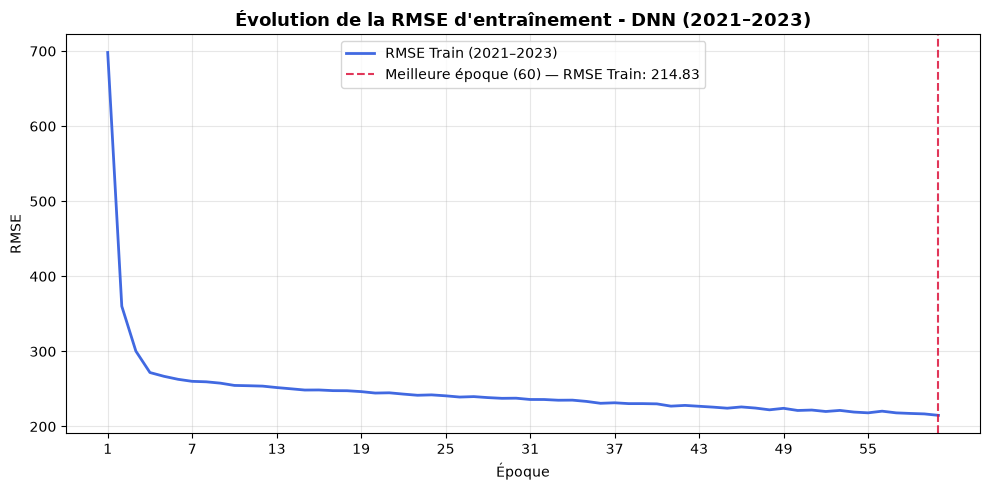

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history["rmse"]) + 1)
best_epoch = int(np.argmin(history.history["rmse"])) + 1
best_rmse = min(history.history["rmse"])

plt.figure(figsize=(10, 5))
plt.plot(
    epochs,
    history.history["rmse"],
    label="RMSE Train (2021–2023)",
    color="royalblue",
    linewidth=2,
)
plt.axvline(
    best_epoch,
    color="crimson",
    linestyle="--",
    alpha=0.85,
    label=f"Meilleure époque ({best_epoch}) — RMSE Train: {best_rmse:.2f}",
)

plt.title(
    "Évolution de la RMSE d'entraînement - DNN (2021–2023)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Époque")
plt.ylabel("RMSE")
plt.xticks(range(1, len(epochs) + 1, max(1, len(epochs) // 10)))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Analyse des résidus (Erreurs de prédiction)

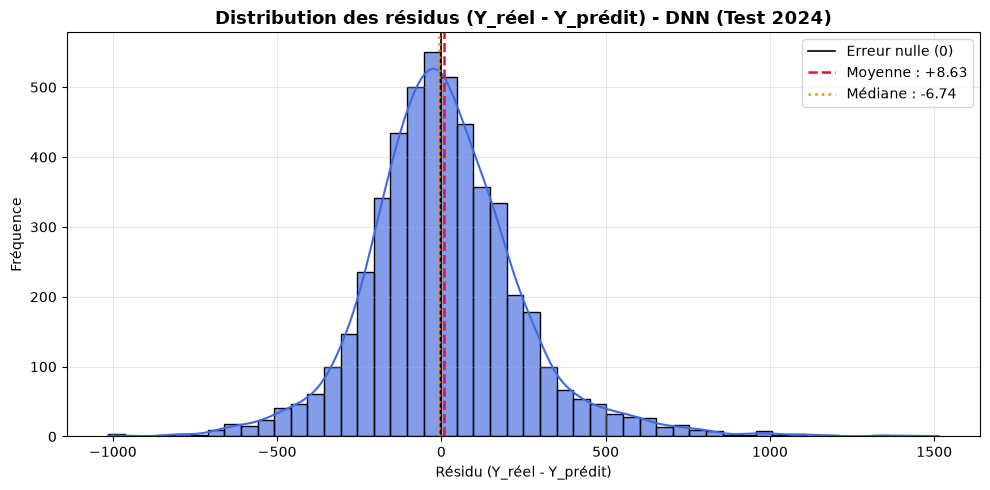

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Calcul des résidus sur le jeu de test (2024) : positif = sous-estimation du modèle
residuals = np.asarray(y_test).ravel() - np.asarray(y_pred_test).ravel()
mean_res = np.mean(residuals)
median_res = np.median(residuals)

# Tracé de la distribution
plt.figure(figsize=(10, 5))
sns.histplot(residuals, kde=True, bins=50, color="royalblue", alpha=0.65)
plt.axvline(
    0, color="black", linestyle="-", linewidth=1.2, label="Erreur nulle (0)"
)
plt.axvline(
    mean_res,
    color="crimson",
    linestyle="--",
    linewidth=1.8,
    label=f"Moyenne : {mean_res:+.2f}",
)
plt.axvline(
    median_res,
    color="darkorange",
    linestyle=":",
    linewidth=1.8,
    label=f"Médiane : {median_res:+.2f}",
)

plt.title(
    "Distribution des résidus (Y_réel - Y_prédit) - DNN (Test 2024)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Résidu (Y_réel - Y_prédit)")
plt.ylabel("Fréquence")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Graphique de parité (Valeurs Réelles vs Prédites)

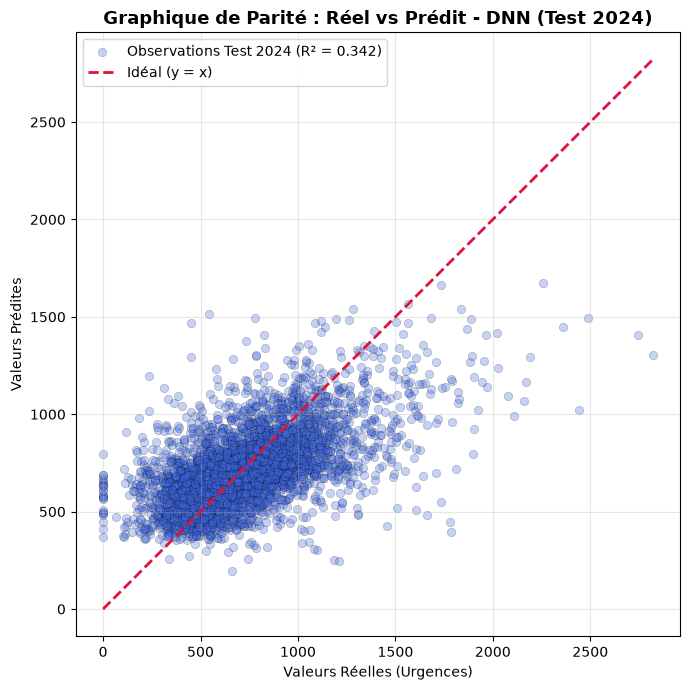

In [19]:
# Sécurisation en vecteurs 1D sur le Test (2024)
y_true_1d = np.asarray(y_test).ravel()
y_pred_1d = np.asarray(y_pred_test).ravel()
r2_test = r2_score(y_true_1d, y_pred_1d)

# Tracé du graphique de parité
plt.figure(figsize=(7, 7))
plt.scatter(
    y_true_1d,
    y_pred_1d,
    alpha=0.3,
    color="royalblue",
    edgecolor="k",
    linewidth=0.4,
    label=f"Observations Test 2024 (R² = {r2_test:.3f})",
)

# Ligne idéale y = x
min_val = min(y_true_1d.min(), y_pred_1d.min())
max_val = max(y_true_1d.max(), y_pred_1d.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="crimson",
    linestyle="--",
    linewidth=2,
    label="Idéal (y = x)",
)

plt.title(
    "Graphique de Parité : Réel vs Prédit - DNN (Test 2024)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Valeurs Réelles (Urgences)")
plt.ylabel("Valeurs Prédites")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

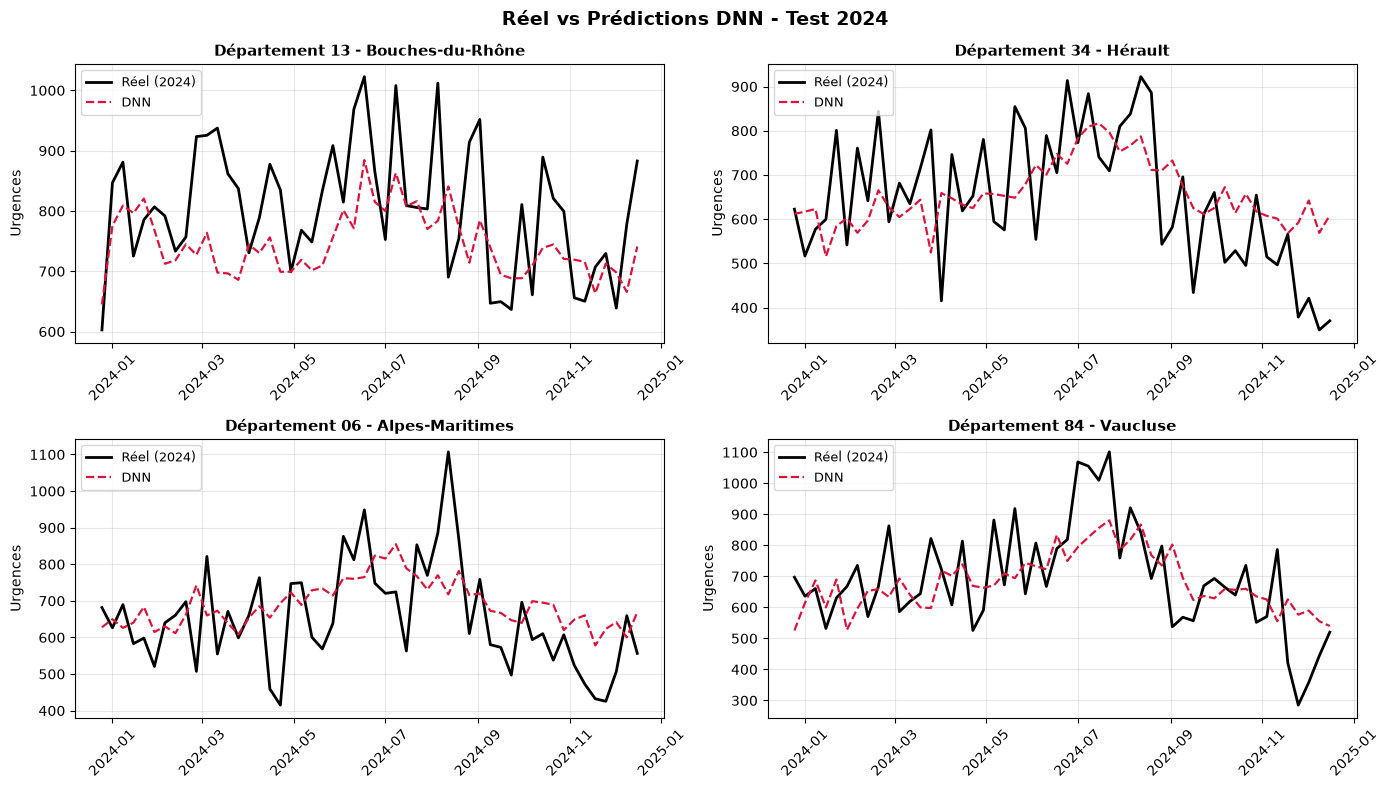

In [20]:
import matplotlib.dates as mdates

def parse_semaine_iso(serie):
  # Convertit "2023-S52" -> "2023-W52-1" (lundi de la semaine ISO)
  s_iso = serie.astype(str).str.replace("-S", "-W", regex=False) + "-1"
  return pd.to_datetime(s_iso, format="%G-W%V-%u")


# 1. Préparation du DataFrame de test (2024)
df_test_viz = test.copy()
df_test_viz["y_reel"] = y_test
df_test_viz["pred_dnn"] = y_pred_test
df_test_viz["date_semaine"] = parse_semaine_iso(df_test_viz["date_semaine"])

depts_cibles = ["13", "34", "06", "84"]
noms_depts = {
    "13": "13 - Bouches-du-Rhône",
    "34": "34 - Hérault",
    "06": "06 - Alpes-Maritimes",
    "84": "84 - Vaucluse",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=False)
axes = axes.flatten()

for i, dept in enumerate(depts_cibles):
  ax = axes[i]
  sub_df = df_test_viz[df_test_viz["code_dept"] == dept].sort_values(
      "date_semaine"
  )

  ax.plot(
      sub_df["date_semaine"],
      sub_df["y_reel"],
      label="Réel (2024)",
      color="black",
      linewidth=2,
  )
  ax.plot(
      sub_df["date_semaine"],
      sub_df["pred_dnn"],
      label="DNN",
      color="crimson",
      linestyle="--",
      linewidth=1.6,
  )

  ax.set_title(
      f"Département {noms_depts.get(dept, dept)}",
      fontsize=11,
      fontweight="bold",
  )
  ax.set_ylabel("Urgences")
  ax.legend(loc="upper left", fontsize=9)
  ax.grid(True, alpha=0.3)

  ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
  ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
  ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Réel vs Prédictions DNN - Test 2024", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

Permutation importance

In [21]:
from sklearn.inspection import permutation_importance

# Scorer basé sur la RMSE négative (plus la valeur baisse, plus la dégradation est forte)
def keras_rmse_scorer(estimator, X, y):
  preds = estimator.predict(X, verbose=0).flatten()
  return -np.sqrt(mean_squared_error(y, preds))


# Nettoyage des noms de features issus du ColumnTransformer
feature_names = [
    col.split("__")[-1] for col in preprocessor_dnn.get_feature_names_out()
]

# Calcul de la permutation importance sur le Test (2024)
result = permutation_importance(
    model,
    X_test_dnn,
    y_test,
    scoring=keras_rmse_scorer,
    n_repeats=15,
    random_state=42,
    n_jobs=1,
)

# Structuration dans un DataFrame propre (tri croissant : impact négatif le plus fort en premier)
importances_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std,
    "rmse_increase": -result.importances_mean,  # <-- AJOUT : hausse directe de RMSE (+ passages)
}).sort_values(by="importance_mean", ascending=True)

print("Top 15 des features les plus critiques (DNN Régression - Test 2024) :")
print(importances_df.head(15).to_string(index=False))

Top 15 des features les plus critiques (DNN Régression - Test 2024) :
                                  feature  importance_mean  importance_std  rmse_increase
                         pct_agriculteurs        -0.823139        0.236255       0.823139
prev_calc_Maladie_Respi_Chronique_15-64_9        -0.742724        0.211262       0.742724
                               Chl in PM1        -0.741306        0.544355       0.741306
                             code_dept_36        -0.460931        0.072203       0.460931
                             code_dept_18        -0.427187        0.098484       0.427187
                               SO4 in PM1        -0.397512        0.461368       0.397512
                               Ni in PM10        -0.372711        0.242481       0.372711
                             code_dept_19        -0.279926        0.143060       0.279926
                         tp_temps_inconnu        -0.227980        0.199566       0.227980
                      lag_1_se

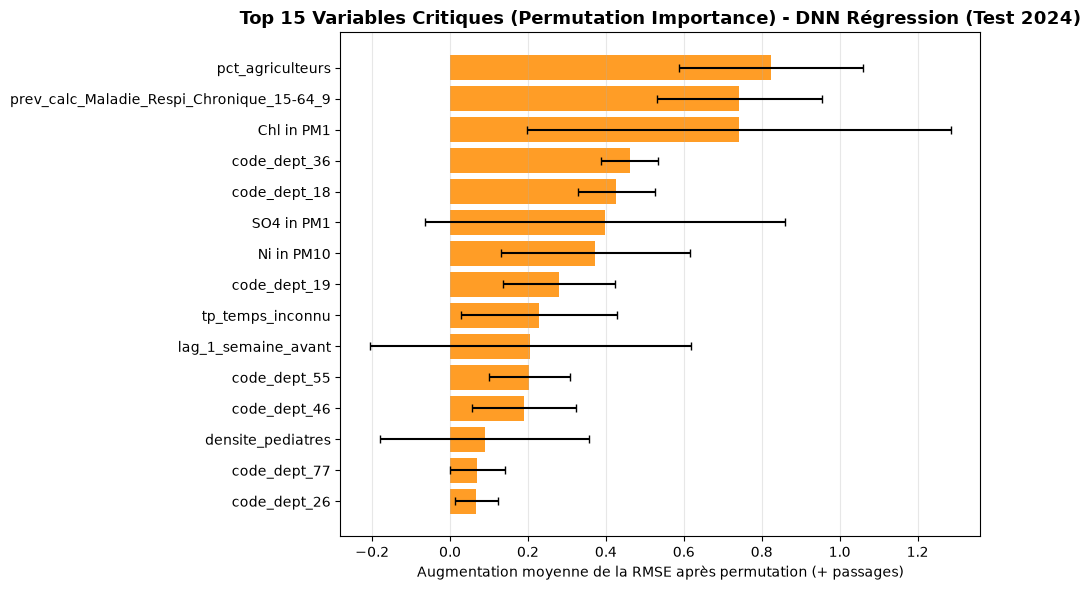

In [22]:
# Sélection du Top 15 (déjà trié par importance_mean croissant dans importances_df)
top_features = importances_df.head(15).copy()
top_features["rmse_increase"] = -top_features["importance_mean"]

# Ordre du bas vers le haut dans barh : la plus critique en haut
top_plot = top_features.iloc[::-1]

# Tracé avec barres d'erreur (écart-type sur les répétitions)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top_plot["feature"],
    top_plot["rmse_increase"],
    xerr=top_plot["importance_std"],
    color="darkorange",
    alpha=0.85,
    ecolor="black",
    capsize=3,
)

ax.set_title(
    "Top 15 Variables Critiques (Permutation Importance) - DNN Régression (Test"
    " 2024)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Augmentation moyenne de la RMSE après permutation (+ passages)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

In [ ]:
#export modele entrainer pour le Streamlit
import joblib

joblib.dump(, "../streamlit/modeles/DNNfinal.pkl")